# Solutions to the exercises of Chapter 2

Sample solutions for [Chapter 2, Onsager's kinetic equations](../../notebooks/part1_principle/02_kinetic_equations.ipynb).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import solve_ivp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## Exercise 1. Any rod

With $t = \tan\theta$ and $\rho = \zeta_\perp/\zeta_\parallel$, the result of Section 2.2
is

$$ \tan\alpha = \frac{(\rho - 1)\sin\theta\cos\theta}{\rho\cos^2\theta + \sin^2\theta} = \frac{(\rho - 1)\,t}{\rho + t^2} . $$

Its derivative with respect to $t$ vanishes where $\rho + t^2 - 2t^2 = 0$, that is,
at $t = \sqrt\rho$, and there

$$ \tan\alpha_{\max} = \frac{\rho - 1}{2\sqrt\rho} . $$

For $\rho = 2$ this is $1/2\sqrt2$, or $\alpha_{\max} = 19.5^\circ$; for $\rho = 3$ it is
$1/\sqrt3$, or $30^\circ$. A sphere ($\rho = 1$) does not drift.

In [2]:
t, rho = sp.symbols("t rho", positive=True)
tan_alpha = (rho - 1) * t / (rho + t**2)
t_star = sp.solve(sp.diff(tan_alpha, t), t)
print("stationary at t =", t_star, "   tan(alpha_max) =", sp.simplify(tan_alpha.subs(t, t_star[0])))
th = np.linspace(0, np.pi / 2, 400001)[:-1]
for r in (1.5, 2.0, 3.0):
    numerical = np.degrees(np.arctan(np.max((r - 1) * np.tan(th) / (r + np.tan(th) ** 2))))
    print(f"rho = {r}:  numerical search {numerical:.4f} deg,  formula {np.degrees(np.arctan((r - 1) / (2 * np.sqrt(r)))):.4f} deg")

stationary at t = [sqrt(rho)]    tan(alpha_max) = (rho - 1)/(2*sqrt(rho))
rho = 1.5:  numerical search 11.5370 deg,  formula 11.5370 deg
rho = 2.0:  numerical search 19.4712 deg,  formula 19.4712 deg
rho = 3.0:  numerical search 30.0000 deg,  formula 30.0000 deg


## Exercise 2. Side by side

Let the spheres be at the same height, a horizontal distance $r$ apart, with heights
$z_1$ and $z_2$. For motion perpendicular to the line of centres the mobility matrix
is

$$ \mu = \frac{1}{6\pi\eta a}\begin{pmatrix} 1 & 3a/4r \\ 3a/4r & 1 \end{pmatrix} , $$

and $A = W(z_1 + z_2)$. Equation (2.5) gives
$\dot z_1 = \dot z_2 = -W\,(1 + 3a/4r)/6\pi\eta a$. The pair falls faster than a single
sphere by the factor $1 + 3a/4r$, half the enhancement found for spheres one above
the other. To this order a vertical force produces no horizontal velocity at the
position of the other sphere, and the two vertical velocities are equal, so the
separation does not change. (Units in the cell: $a = 1$, $6\pi\eta a = 1$.)

In [3]:
z1, z2, w1, w2 = sp.symbols("z1 z2 w1 w2")
W, r = sp.symbols("W r", positive=True)
mobility = sp.Matrix([[1, sp.Rational(3, 4) / r], [sp.Rational(3, 4) / r, 1]])
rates = sp.Matrix([w1, w2])
eq = on.kinetic_equations(W * (z1 + z2), (rates.T * mobility.inv() * rates)[0] / 2, [z1, z2], [w1, w2])
print("zdot_1 =", sp.factor(eq[w1]), "   zdot_2 =", sp.factor(eq[w2]))

zdot_1 = -W*(4*r + 3)/(4*r)    zdot_2 = -W*(4*r + 3)/(4*r)


## Exercise 3. Three variables

Three spheres on a vertical line, with $z_1 < z_2 < z_3$. With pairwise far-field
interactions the mobility matrix has unit diagonal and off-diagonal elements
$3a/2r_{ij}$, where $r_{ij}$ is the distance between spheres $i$ and $j$, and

$$ A = W(z_1 + z_2 + z_3) + \tfrac12k\,(z_2 - z_1 - r_0)^2 + \tfrac12k\,(z_3 - z_2 - r_0)^2 . $$

`on.kinetic_equations` needs $\Phi = \tfrac12\dot{\mathbf z}^{\mathsf T}\mu^{-1}\dot{\mathbf z}$,
and the symbolic inverse of a $3\times3$ matrix whose elements depend on the state is
slow to simplify. Nothing is lost by using the mobility form (2.5) directly,
$\dot{\mathbf z} = -\mu\,\nabla A$, which is the same statement. The cell integrates
it, checks at one state that the rates satisfy the friction form (2.4), and
verifies the energy balance.

In [4]:
Wn, kn, r0n = 1.0, 0.5, 4.0


def mobility3(z):
    M = np.eye(3)
    for i in range(3):
        for j in range(3):
            if i != j:
                M[i, j] = 1.5 / abs(z[i] - z[j])
    return M


def grad_A(z):
    s1, s2 = z[1] - z[0] - r0n, z[2] - z[1] - r0n
    return np.array([Wn - kn * s1, Wn + kn * (s1 - s2), Wn + kn * s2])


free_energy = lambda z: Wn * z.sum(axis=0) + 0.5 * kn * ((z[1] - z[0] - r0n) ** 2 + (z[2] - z[1] - r0n) ** 2)
rhs = lambda t, z: -mobility3(z) @ grad_A(z)

tt = np.linspace(0, 12, 4801)
sol = solve_ivp(rhs, (0, 12), [0.0, 9.0, 15.0], t_eval=tt, rtol=1e-11, atol=1e-13)
z = sol.y
two_Phi = np.array([grad_A(z[:, i]) @ mobility3(z[:, i]) @ grad_A(z[:, i]) for i in range(len(tt))])
dissipated = np.concatenate(([0.0], np.cumsum(0.5 * (two_Phi[1:] + two_Phi[:-1]) * np.diff(tt))))
A_t = free_energy(z)

z_test = z[:, 100]
zeta = np.linalg.inv(mobility3(z_test))
print("friction form (2.4) at one state, zeta zdot + grad A:", np.round(zeta @ rhs(0, z_test) + grad_A(z_test), 14))
print(f"separations at the end: {z[1, -1] - z[0, -1]:.4f}, {z[2, -1] - z[1, -1]:.4f}   (r0 = {r0n})")
print(f"largest |A(0) - A(t) - integral of 2 Phi|: {on.sup_error(A_t[0] - A_t, dissipated):.1e}   (A falls by {A_t[0] - A_t[-1]:.2f})")
print("velocities at the end (single sphere = -1):", np.round(rhs(0, z[:, -1]), 4))

friction form (2.4) at one state, zeta zdot + grad A: [-0.  0.  0.]
separations at the end: 3.8423, 4.2724   (r0 = 4.0)
largest |A(0) - A(t) - integral of 2 Phi|: 7.3e-06   (A falls by 62.89)
velocities at the end (single sphere = -1): [-1.5953 -1.605  -1.6112]


The energy balance holds to the accuracy of the time integration. With three
spheres the hydrodynamic forces are no longer the same on each: the middle sphere
has two near neighbours and would fall fastest if free. The springs therefore
settle slightly away from their rest length, compressed below the middle sphere
and stretched above it (3.84 and 4.27 here, against a rest length of 4), so that
all three fall together. At $t = 12$ the three velocities agree to about 1 % and are
still converging. Two spheres cannot show this.

## Exercise 4. A matrix that is not symmetric

The force balance $\zeta\dot{\mathbf x} = -\nabla A$ with
$\zeta = \begin{pmatrix} 1 & \epsilon \\ -\epsilon & 1 \end{pmatrix}$ gives

$$ \dot A = \nabla A\cdot\dot{\mathbf x} = -\dot{\mathbf x}^{\mathsf T}\zeta^{\mathsf T}\dot{\mathbf x} = -\dot{\mathbf x}\cdot\dot{\mathbf x} \le 0 , $$

because the antisymmetric part of $\zeta$ contributes nothing to a quadratic form.
The free energy still decreases.

The Rayleighian built from the same matrix is
$R = \tfrac12\dot{\mathbf x}^{\mathsf T}\zeta\dot{\mathbf x} + \nabla A\cdot\dot{\mathbf x} = \tfrac12\dot{\mathbf x}\cdot\dot{\mathbf x} + \nabla A\cdot\dot{\mathbf x}$,
for the same reason, and its minimum is $\dot{\mathbf x} = -\nabla A$: the equations
with $\epsilon = 0$. The antisymmetric part, which changes the motion (it turns the
velocity away from the direction of steepest descent), is invisible to the
Rayleighian. A force balance with a non-symmetric friction matrix cannot be
obtained from a minimum principle of this kind; conversely, Onsager's theorem says
that for systems with microscopic reversibility such a matrix does not occur.

A decreases along the force-balance solution: True
A decreases along the Rayleighian solution:   True
largest distance between the two trajectories: 0.529


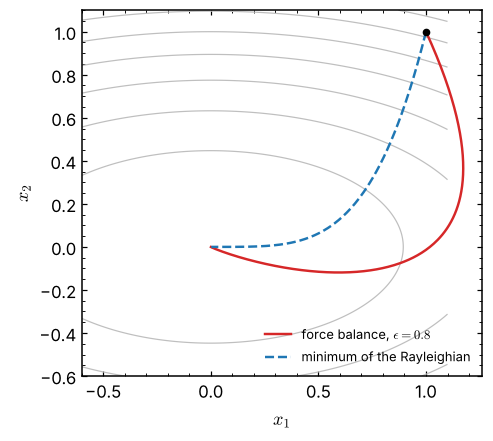

In [5]:
eps = 0.8
zeta_ns = np.array([[1.0, eps], [-eps, 1.0]])
gradA = lambda x: np.array([x[0], 4 * x[1]])
A2 = lambda x: 0.5 * (x[0] ** 2 + 4 * x[1] ** 2)
tt2 = np.linspace(0, 6, 601)
balance = solve_ivp(lambda t, x: -np.linalg.solve(zeta_ns, gradA(x)), (0, 6), [1.0, 1.0], t_eval=tt2, rtol=1e-10, atol=1e-12)
minimum = solve_ivp(lambda t, x: -gradA(x), (0, 6), [1.0, 1.0], t_eval=tt2, rtol=1e-10, atol=1e-12)
print("A decreases along the force-balance solution:", bool(np.all(np.diff(A2(balance.y)) < 0)))
print("A decreases along the Rayleighian solution:  ", bool(np.all(np.diff(A2(minimum.y)) < 0)))
print(f"largest distance between the two trajectories: {np.max(np.hypot(*(balance.y - minimum.y))):.3f}")

fig, ax = plt.subplots(figsize=(4.8, 3.9))
g = np.linspace(-0.6, 1.1, 200)
GX, GY = np.meshgrid(g, g)
ax.contour(GX, GY, A2(np.array([GX, GY])), levels=8, colors="0.75", linewidths=0.8)
ax.plot(*balance.y, color="C3", label=rf"force balance, $\epsilon = {eps}$")
ax.plot(*minimum.y, "--", color="C0", label="minimum of the Rayleighian")
ax.plot(1, 1, "ko", ms=4)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal"); ax.legend(loc="lower right", fontsize=8.5)
plt.show()